In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root from the notebook directory
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "archive-3"
    / "city_day.csv"
)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("Cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Project root: /Users/ashokreddy/india-air-pollution-analysis
Dataset exists: True

Dataset loaded successfully!
Shape: (29531, 16)
Cities: 26
Date range: 2015-01-01 to 2020-07-01


In [3]:
missing_audit = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100,
    "Available Values": df.notna().sum()
})

missing_audit = missing_audit.sort_values(
    "Missing Percentage",
    ascending=False
)

missing_audit.round(2)

,Missing Count,Missing Percentage,Available Values
Xylene,18109,61.32,11422
PM10,11140,37.72,18391
NH3,10328,34.97,19203
Toluene,8041,27.23,21490
Benzene,5623,19.04,23908
AQI,4681,15.85,24850
AQI_Bucket,4681,15.85,24850
PM2.5,4598,15.57,24933
NOx,4185,14.17,25346
O3,4022,13.62,25509


In [4]:
city_coverage = (
    df.groupby("City")
    .agg(
        Total_Records=("Date", "size"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        AQI_Available=("AQI", "count"),
        PM25_Available=("PM2.5", "count"),
        PM10_Available=("PM10", "count")
    )
    .sort_values("Total_Records", ascending=False)
)

city_coverage

,Total_Records,First_Date,Last_Date,AQI_Available,PM25_Available,PM10_Available
City,,,,,,
Ahmedabad,2009,2015-01-01,2020-07-01,1334,1381,407
Delhi,2009,2015-01-01,2020-07-01,1999,2007,1932
Mumbai,2009,2015-01-01,2020-07-01,775,784,763
Bengaluru,2009,2015-01-01,2020-07-01,1910,1863,1649
Lucknow,2009,2015-01-01,2020-07-01,1893,1907,0
Chennai,2009,2015-01-01,2020-07-01,1884,1892,302
Hyderabad,2006,2015-01-04,2020-07-01,1880,1891,1651
Patna,1858,2015-06-01,2020-07-01,1459,1537,191
Gurugram,1679,2015-11-27,2020-07-01,1453,1525,740


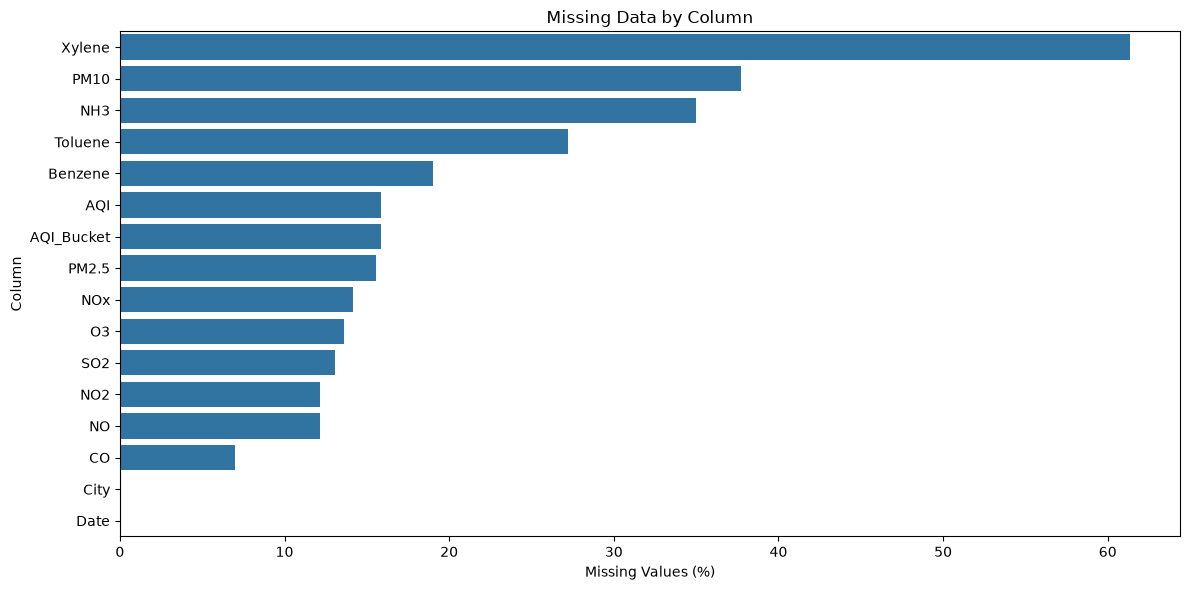

In [5]:
missing_percent = (
    df.isna().mean().mul(100).sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Data by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [6]:
# Convert Date into a proper datetime column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Extract year
df["Year"] = df["Date"].dt.year

# Calculate missing AQI percentage by year
yearly_missing_aqi = (
    df.groupby("Year")["AQI"]
    .agg(
        Total_Records="size",
        Available_AQI="count"
    )
)

yearly_missing_aqi["Missing_AQI_Percent"] = (
    100
    * (yearly_missing_aqi["Total_Records"]
       - yearly_missing_aqi["Available_AQI"])
    / yearly_missing_aqi["Total_Records"]
)

yearly_missing_aqi.round(2)

,Total_Records,Available_AQI,Missing_AQI_Percent
Year,,,
2015,2801,1827,34.77
2016,3478,2573,26.02
2017,4689,3234,31.03
2018,6471,5724,11.54
2019,7446,7071,5.04
2020,4646,4421,4.84


In [7]:
city_aqi_quality = (
    df.groupby("City")["AQI"]
    .agg(
        Total_Records="size",
        Available_AQI="count"
    )
)

city_aqi_quality["Missing_AQI_Percent"] = (
    100
    * (city_aqi_quality["Total_Records"]
       - city_aqi_quality["Available_AQI"])
    / city_aqi_quality["Total_Records"]
)

city_aqi_quality = city_aqi_quality.sort_values(
    "Missing_AQI_Percent",
    ascending=False
)

city_aqi_quality.round(2)

,Total_Records,Available_AQI,Missing_AQI_Percent
City,,,
Mumbai,2009,775,61.42
Jorapokhar,1169,771,34.05
Shillong,310,205,33.87
Ahmedabad,2009,1334,33.60
Talcher,925,698,24.54
Brajrajnagar,938,713,23.99
Patna,1858,1459,21.47
Visakhapatnam,1462,1171,19.90
Gurugram,1679,1453,13.46


In [8]:
duplicate_city_dates = df.duplicated(
    subset=["City", "Date"],
    keep=False
)

print(
    "Rows involved in duplicate city-date combinations:",
    duplicate_city_dates.sum()
)

if duplicate_city_dates.any():
    display(
        df.loc[duplicate_city_dates]
        .sort_values(["City", "Date"])
        .head(20)
    )
else:
    print("Every city-date combination is unique.")

Rows involved in duplicate city-date combinations: 0
Every city-date combination is unique.


In [9]:
# Count available AQI observations for every city-year pair
aqi_city_year = (
    df.pivot_table(
        index="City",
        columns="Year",
        values="AQI",
        aggfunc="count"
    )
    .fillna(0)
    .astype(int)
)

aqi_city_year

Year,2015,2016,2017,2018,2019,2020
City,,,,,,
Ahmedabad,263,117,69,357,352,176
Aizawl,0,0,0,0,0,111
Amaravati,0,0,37,312,309,183
Amritsar,0,0,266,324,362,174
Bengaluru,286,351,364,361,365,183
Bhopal,0,0,0,0,105,173
Brajrajnagar,0,0,10,260,322,121
Chandigarh,0,0,0,0,117,182
Chennai,276,334,361,365,365,183


In [10]:
city_aqi_summary = (
    df.groupby("City")
    .agg(
        Total_Records=("AQI", "size"),
        Available_AQI=("AQI", "count"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max")
    )
)

city_aqi_summary["AQI_Coverage_Percent"] = (
    city_aqi_summary["Available_AQI"]
    / city_aqi_summary["Total_Records"]
    * 100
)

city_aqi_summary = city_aqi_summary.sort_values(
    "AQI_Coverage_Percent",
    ascending=False
)

city_aqi_summary.round(2)

/var/folders/db/8j7j11tx76db2fppvdn17hkm0000gn/T/ipykernel_2542/3518855499.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  city_aqi_summary.round(2)


,Total_Records,Available_AQI,First_Date,Last_Date,AQI_Coverage_Percent
City,,,,,
Delhi,2009,1999,2015-01-01,2020-07-01,99.50
Guwahati,502,495,2019-02-16,2020-07-01,98.61
Chandigarh,304,299,2019-09-02,2020-07-01,98.36
Aizawl,113,111,2020-03-11,2020-07-01,98.23
Jaipur,1114,1094,2017-06-14,2020-07-01,98.20
Kochi,162,158,2020-01-22,2020-07-01,97.53
Bhopal,289,278,2019-09-17,2020-07-01,96.19
Bengaluru,2009,1910,2015-01-01,2020-07-01,95.07
Thiruvananthapuram,1112,1052,2017-06-16,2020-07-01,94.60


In [11]:
from pathlib import Path

TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

missing_audit.to_csv(
    TABLES_DIR / "missing_values_audit.csv"
)

city_coverage.to_csv(
    TABLES_DIR / "city_coverage_audit.csv"
)

yearly_missing_aqi.to_csv(
    TABLES_DIR / "yearly_aqi_missingness.csv"
)

city_aqi_summary.to_csv(
    TABLES_DIR / "city_aqi_completeness.csv"
)

aqi_city_year.to_csv(
    TABLES_DIR / "aqi_coverage_by_city_year.csv"
)

print("Audit tables exported to:", TABLES_DIR)
print("Files saved: 5")

Audit tables exported to: /Users/ashokreddy/india-air-pollution-analysis/outputs/tables
Files saved: 5
